# Distributions of influent concentrations, by year

Public WWTPs with capacity ≥ 500 m³/day. A value of 0 means "not measured" and is left out.
One figure per year; figures are saved to `figures/` (PNG and PDF, 600 dpi).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from seaborn.external.kde import gaussian_kde   # smooth curve (same as scipy's gaussian_kde)

# Journal-style figure settings
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 9,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})

years = [2020, 2021, 2023, 2024, 2025]   # 2022 is missing (its file is a copy of 2021)
params = {                               # short name: (column in the file, axis label)
    "BOD":    ("Influent_Biochemical Oxygen Demand (BOD)", "BOD"),
    "COD_Mn": ("Influent_Chemical Oxygen Demand (COD)",    "COD$_{Mn}$"),   # 2020 only
    "TOC":    ("Influent_Total Organic Carbon (TOC)",      "TOC"),          # 2021 onward
    "T-N":    ("Influent_Total Nitrogen (T-N)",            "T-N"),
    "T-P":    ("Influent_Total Phosphorus (T-P)",          "T-P"),
}

In [2]:
data = []
for year in years:
    df = pd.read_csv(f"../data/{year}/translated_{year}1231.csv")
    df = df[df["Facility Capacity"] >= 500]   # large plants only
    df["year"] = year
    data.append(df)
data = pd.concat(data)

# Same bins for a parameter in every year, with round widths (mg/L) so each bar is an easy range
bin_width = {"BOD": 20, "COD_Mn": 10, "TOC": 10, "T-N": 5, "T-P": 0.5}
bins, x_limit = {}, {}
for name, (column, _) in params.items():
    values = data[column][data[column] > 0]
    width = bin_width[name]
    bins[name] = np.arange(0, values.max() + width, width)    # covers every value
    x_limit[name] = values.quantile(0.995) * 1.15              # plot range (full range is in the stats box)

In [3]:
def plot_distribution(ax, values, name, label):
    decimals = 2 if name == "T-P" else 1
    q1, median, q3 = values.quantile([0.25, 0.5, 0.75])
    mean, sd = values.mean(), values.std()

    ax.axvspan(q1, q3, color="0.88", zorder=0, label="IQR (P25–P75)")
    # Bars: % of plants in each range (each year adds up to 100 %)
    ax.hist(values, bins=bins[name], weights=np.full(len(values), 100 / len(values)),
            color="#9ec5f4", edgecolor="white", linewidth=0.4, label="Histogram")
    # Smooth curve, scaled to the same % per bar
    x = np.linspace(values.min(), values.max(), 300)
    ax.plot(x, gaussian_kde(values)(x) * bin_width[name] * 100, color="#184f95", linewidth=1.4,
            label="Kernel density")
    ax.axvline(median, color="black", linewidth=1.2, label="Median")
    ax.axvline(mean, color="#eb6834", linewidth=1.2, linestyle="--", label="Mean")

    f = f".{decimals}f"
    stats = (f"n = {len(values)}\n"
             f"Mean ± SD = {mean:{f}} ± {sd:{f}}\n"
             f"Median = {median:{f}}\n"
             f"IQR = {q1:{f}}–{q3:{f}}\n"
             f"Range = {values.min():{f}}–{values.max():{f}}\n"
             f"Skewness = {values.skew():.2f}")
    ax.text(1.03, 1.0, stats, transform=ax.transAxes, ha="left", va="top", fontsize=7.5,   # beside the plot
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="0.7", linewidth=0.6))

    ax.set_xlim(0, x_limit[name])
    ax.set_xlabel(f"Influent {label} (mg L$^{{-1}}$)")
    ax.set_ylabel("Plants (%)")

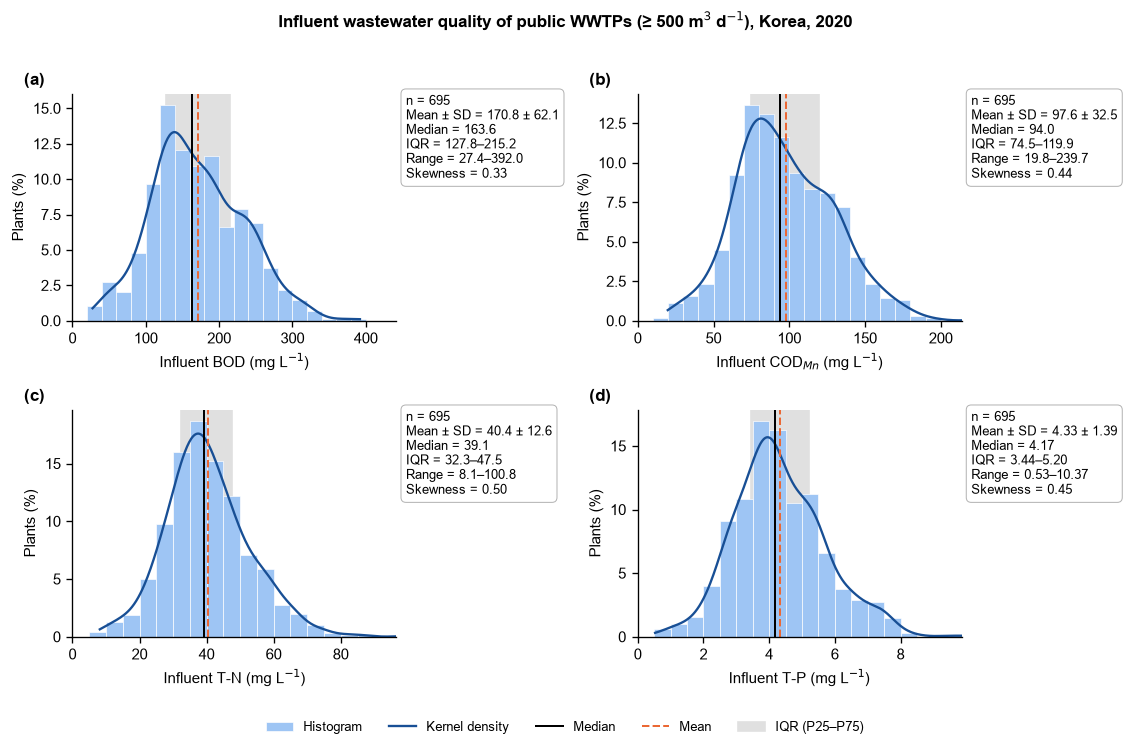

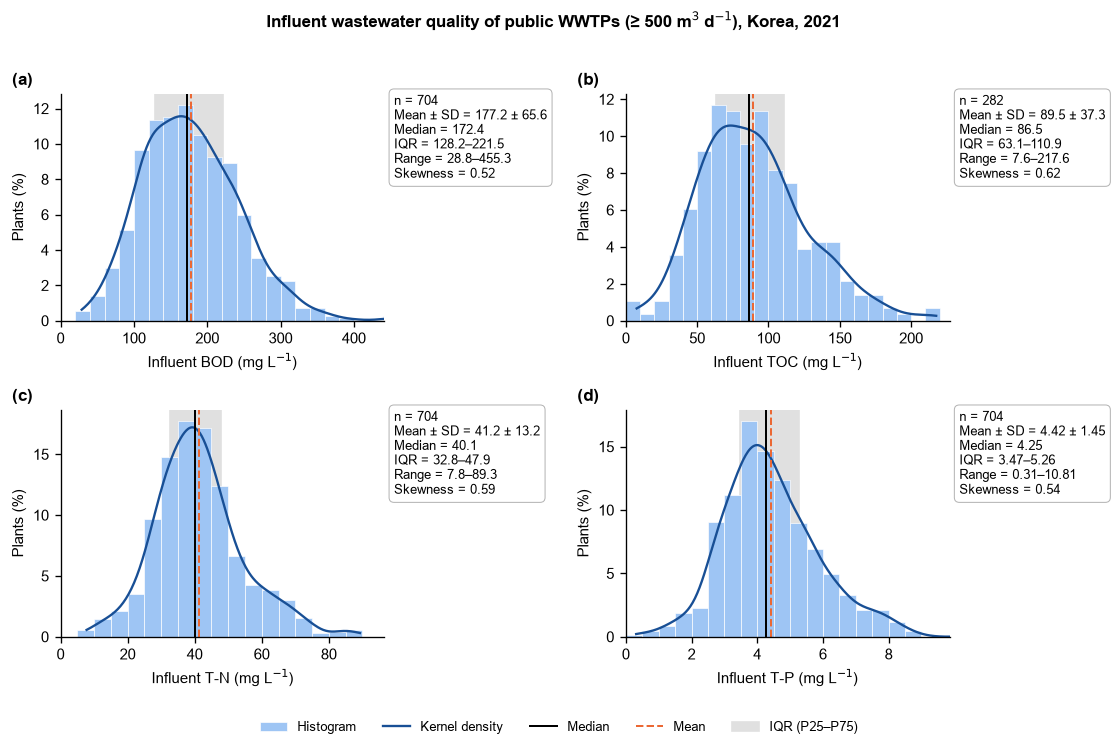

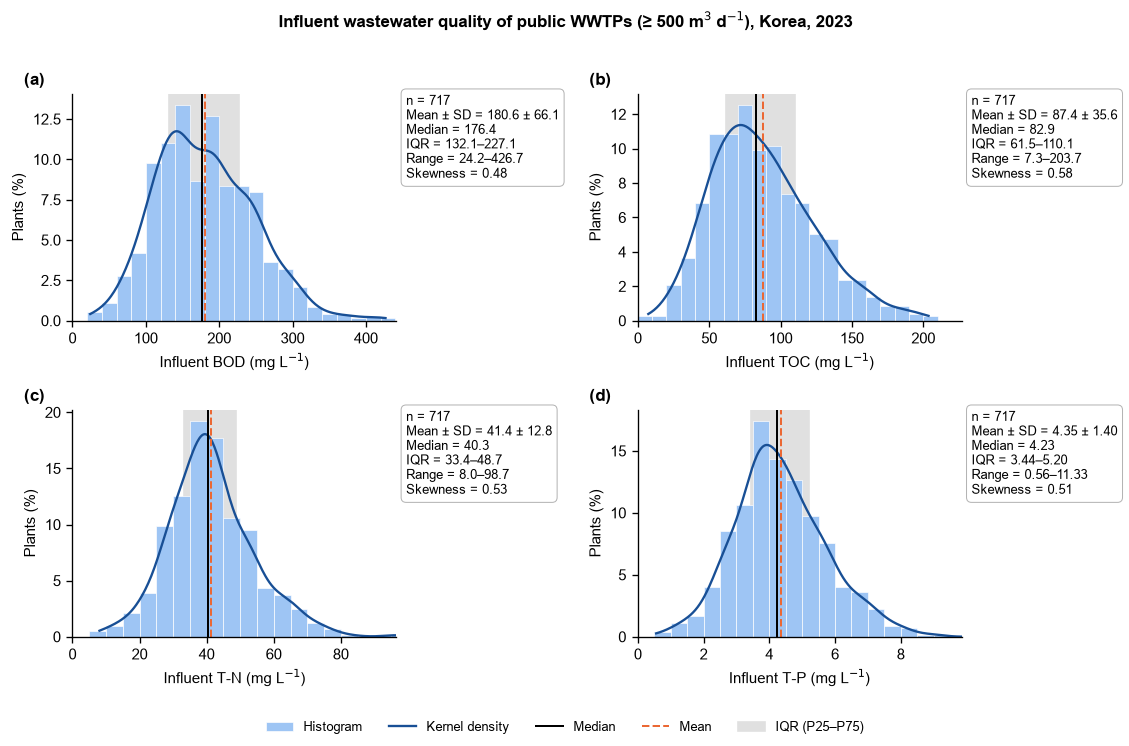

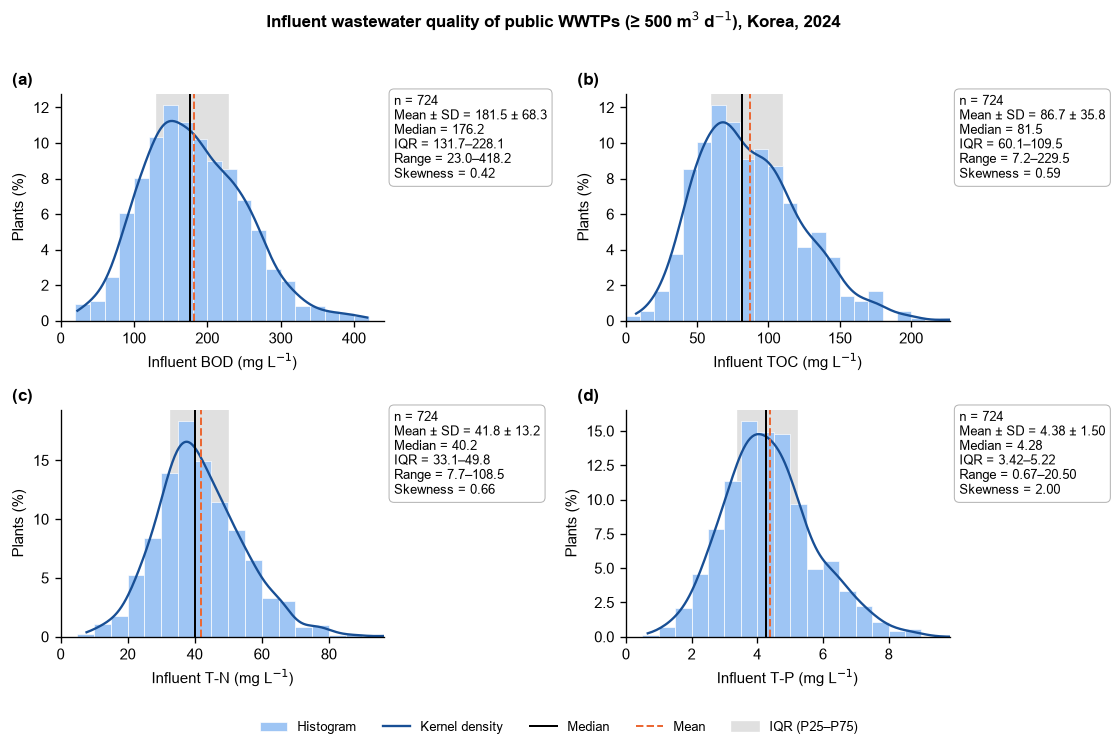

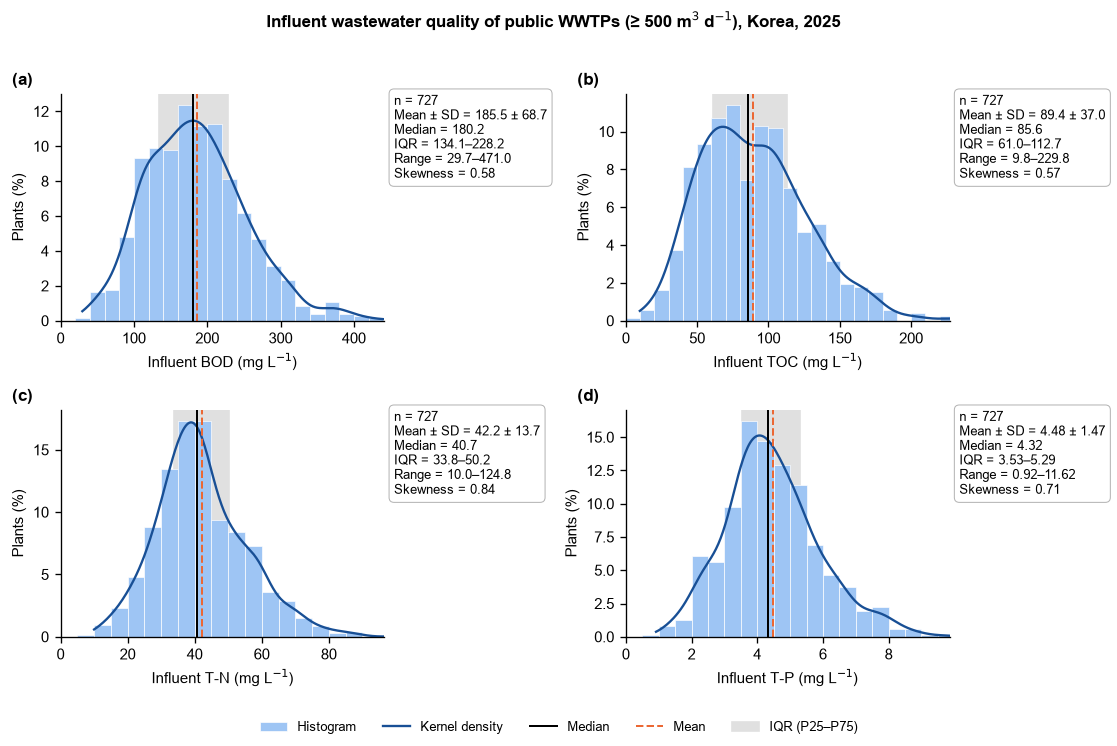

In [4]:
Path("../figures").mkdir(exist_ok=True)

for year in years:
    d = data[data["year"] == year]
    measured = [name for name, (column, _) in params.items() if (d[column] > 0).any()]

    fig, axes = plt.subplots(2, 2, figsize=(9.5, 6.2))
    for ax, letter, name in zip(axes.flat, "abcd", measured):
        column, label = params[name]
        values = d[column][d[column] > 0]
        plot_distribution(ax, values, name, label)
        ax.text(-0.15, 1.04, f"({letter})", transform=ax.transAxes, fontsize=10, fontweight="bold")

    handles, labels = axes[0, 0].get_legend_handles_labels()
    order = ["Histogram", "Kernel density", "Median", "Mean", "IQR (P25–P75)"]
    handles = [handles[labels.index(name)] for name in order]
    fig.legend(handles, order, loc="lower center", ncol=5, frameon=False, fontsize=8)
    fig.suptitle(f"Influent wastewater quality of public WWTPs (≥ 500 m$^3$ d$^{{-1}}$), Korea, {year}",
                 fontsize=10, fontweight="bold")
    fig.tight_layout(rect=[0, 0.05, 1, 0.97])

    fig.savefig(f"../figures/influent_distribution_{year}.png", dpi=600)
    fig.savefig(f"../figures/influent_distribution_{year}.pdf")
    plt.show()

**Figure caption (for the paper):** Distribution of influent concentrations at public wastewater treatment
plants with capacity ≥ 500 m³ d⁻¹ in Korea. Bars show the percentage of plants in each concentration range
(each year sums to 100%), the curve a kernel density estimate scaled to the same units, the solid line the median, the dashed line the mean, and the grey band the interquartile range
(P25–P75). Bin widths are 20 (BOD), 10 (COD$_{Mn}$, TOC), 5 (T-N) and 0.5 mg L⁻¹ (T-P). The x-axis is the
same for each parameter in all years and is cut at 1.15 × the 99.5th percentile
of all years; the full range is given in each panel. COD$_{Mn}$ (permanganate method) was reported only in
2020 and TOC from 2021 (in 2021 by only 282 plants).

## Summary table (all years)

In [5]:
rows = []
for year in years:
    d = data[data["year"] == year]
    for name, (column, _) in params.items():
        values = d[column][d[column] > 0]
        if len(values) == 0:
            continue
        rows.append({"year": year, "parameter": name, "n": len(values),
                     "mean": values.mean(), "SD": values.std(), "median": values.median(),
                     "P25": values.quantile(0.25), "P75": values.quantile(0.75),
                     "min": values.min(), "max": values.max(), "skewness": values.skew()})

summary = pd.DataFrame(rows).set_index(["parameter", "year"]).sort_index().round(2)
summary

n    mean     SD  median     P25     P75    min     max  \
parameter year                                                              
BOD       2020  695  170.79  62.11  163.60  127.85  215.25  27.40  392.00   
          2021  704  177.25  65.60  172.40  128.25  221.48  28.80  455.30   
          2023  717  180.63  66.15  176.40  132.10  227.10  24.20  426.70   
          2024  724  181.49  68.28  176.25  131.67  228.10  23.00  418.20   
          2025  727  185.46  68.68  180.20  134.05  228.25  29.70  471.00   
COD_Mn    2020  695   97.56  32.48   94.00   74.45  119.90  19.80  239.70   
T-N       2020  695   40.39  12.57   39.14   32.30   47.46   8.14  100.76   
          2021  704   41.24  13.20   40.09   32.78   47.87   7.76   89.28   
          2023  717   41.38  12.80   40.27   33.35   48.68   8.04   98.74   
          2024  724   41.76  13.18   40.23   33.06   49.80   7.75  108.49   
          2025  727   42.22  13.72   40.69   33.77   50.17   9.99  124.79   
T-P       2020  695    4.33   1.39    4.18    3.44    5.20   0.53   10.37   
          2021  704    4.42   1.45    4.25    3.47    5.26   0.31   10.81   
          2023  717    4.35   1.40    4.23    3.44    5.20   0.56   11.33   
          2024  724    4.38   1.50    4.28    3.42    5.22   0.67   20.50   
          2025  727    4.48   1.47    4.32    3.53    5.29   0.92   11.62   
TOC       2021  282   89.49  37.27   86.55   63.08  110.95   7.60  217.60   
          2023  717   87.38  35.62   82.90   61.50  110.10   7.30  203.70   
          2024  724   86.74  35.81   81.45   60.08  109.45   7.20  229.50   
          2025  727   89.38  37.00   85.60   61.00  112.65   9.80  229.80   

                skewness  
parameter year            
BOD       2020      0.33  
          2021      0.52  
          2023      0.48  
          2024      0.42  
          2025      0.58  
COD_Mn    2020      0.44  
T-N       2020      0.50  
          2021      0.59  
          2023      0.53  
          2024      0.66  
          2025      0.84  
T-P       2020      0.45  
          2021      0.54  
          2023      0.51  
          2024      2.00  
          2025      0.71  
TOC       2021      0.62  
          2023      0.58  
          2024      0.59  
          2025      0.57

## Histogram ranges: number of plants in each concentration range

Each row is one bar of the histograms above. Cells show **number of plants (% of that year)**.
A range "140–160" includes 140 and excludes 160. The tables are also saved to `tables/`.

In [6]:
Path("../tables").mkdir(exist_ok=True)
range_tables = {}

for name, (column, _) in params.items():
    edges = bins[name]
    decimals = 1 if name == "T-P" else 0
    labels = [f"{a:.{decimals}f}–{b:.{decimals}f}" for a, b in zip(edges[:-1], edges[1:])]

    table = pd.DataFrame(index=labels)
    for year in years:
        values = data.loc[data["year"] == year, column]
        values = values[values > 0]
        if len(values) == 0:
            continue
        counts = pd.cut(values, bins=edges, labels=labels, right=False).value_counts().reindex(labels)
        percent = counts / len(values) * 100
        table[year] = [f"{c} ({p:.1f}%)" if c else "" for c, p in zip(counts, percent)]

    table.index.name = f"{name} (mg/L)"
    table = table[(table != "").any(axis=1)]      # drop ranges with no plants in any year
    table.to_csv(f"../tables/histogram_ranges_{name}.csv", encoding="utf-8-sig")
    range_tables[name] = table

In [7]:
range_tables['BOD']

,2020,2021,2023,2024,2025
BOD (mg/L),,,,,
20–40,7 (1.0%),4 (0.6%),4 (0.6%),7 (1.0%),1 (0.1%)
40–60,19 (2.7%),10 (1.4%),8 (1.1%),8 (1.1%),12 (1.7%)
60–80,14 (2.0%),21 (3.0%),20 (2.8%),18 (2.5%),13 (1.8%)
80–100,33 (4.7%),36 (5.1%),30 (4.2%),44 (6.1%),35 (4.8%)
100–120,67 (9.6%),68 (9.7%),70 (9.8%),58 (8.0%),68 (9.4%)
120–140,106 (15.3%),80 (11.4%),79 (11.0%),75 (10.4%),72 (9.9%)
140–160,84 (12.1%),81 (11.5%),96 (13.4%),88 (12.2%),71 (9.8%)
160–180,76 (10.9%),86 (12.2%),62 (8.6%),81 (11.2%),90 (12.4%)
180–200,81 (11.7%),74 (10.5%),91 (12.7%),74 (10.2%),81 (11.1%)


In [8]:
range_tables['TOC']

,2021,2023,2024,2025
TOC (mg/L),,,,
0–10,3 (1.1%),2 (0.3%),2 (0.3%),1 (0.1%)
10–20,1 (0.4%),2 (0.3%),4 (0.6%),4 (0.6%)
20–30,3 (1.1%),15 (2.1%),12 (1.7%),12 (1.7%)
30–40,10 (3.5%),26 (3.6%),27 (3.7%),27 (3.7%)
40–50,17 (6.0%),49 (6.8%),62 (8.6%),59 (8.1%)
50–60,26 (9.2%),78 (10.9%),73 (10.1%),68 (9.4%)
60–70,33 (11.7%),78 (10.9%),88 (12.2%),78 (10.7%)
70–80,32 (11.3%),90 (12.6%),81 (11.2%),83 (11.4%)
80–90,27 (9.6%),71 (9.9%),66 (9.1%),54 (7.4%)


In [9]:
range_tables['T-N']

,2020,2021,2023,2024,2025
T-N (mg/L),,,,,
5–10,3 (0.4%),4 (0.6%),4 (0.6%),2 (0.3%),1 (0.1%)
10–15,9 (1.3%),10 (1.4%),7 (1.0%),8 (1.1%),7 (1.0%)
15–20,13 (1.9%),15 (2.1%),15 (2.1%),13 (1.8%),17 (2.3%)
20–25,35 (5.0%),25 (3.6%),28 (3.9%),38 (5.2%),35 (4.8%)
25–30,68 (9.8%),68 (9.7%),71 (9.9%),61 (8.4%),64 (8.8%)
30–35,111 (16.0%),104 (14.8%),90 (12.6%),101 (14.0%),98 (13.5%)
35–40,130 (18.7%),125 (17.8%),138 (19.2%),133 (18.4%),126 (17.3%)
40–45,106 (15.3%),121 (17.2%),127 (17.7%),108 (14.9%),126 (17.3%)
45–50,85 (12.2%),87 (12.4%),76 (10.6%),83 (11.5%),68 (9.4%)


In [10]:
range_tables['T-P']

,2020,2021,2023,2024,2025
T-P (mg/L),,,,,
0.0–0.5,,1 (0.1%),,,
0.5–1.0,4 (0.6%),3 (0.4%),3 (0.4%),1 (0.1%),1 (0.1%)
1.0–1.5,7 (1.0%),6 (0.9%),8 (1.1%),5 (0.7%),6 (0.8%)
1.5–2.0,11 (1.6%),13 (1.8%),12 (1.7%),15 (2.1%),9 (1.2%)
2.0–2.5,28 (4.0%),16 (2.3%),29 (4.0%),33 (4.6%),44 (6.1%)
2.5–3.0,63 (9.1%),64 (9.1%),61 (8.5%),57 (7.9%),41 (5.6%)
3.0–3.5,75 (10.8%),79 (11.2%),76 (10.6%),82 (11.3%),71 (9.8%)
3.5–4.0,118 (17.0%),120 (17.0%),125 (17.4%),114 (15.7%),118 (16.2%)
4.0–4.5,113 (16.3%),103 (14.6%),103 (14.4%),108 (14.9%),107 (14.7%)


In [11]:
range_tables['COD_Mn']

,2020
COD_Mn (mg/L),
10–20,1 (0.1%)
20–30,8 (1.2%)
30–40,11 (1.6%)
40–50,16 (2.3%)
50–60,31 (4.5%)
60–70,64 (9.2%)
70–80,95 (13.7%)
80–90,91 (13.1%)
90–100,81 (11.7%)
